# Chapter 10: Plotting with Matplotlib

A table of 366 daily totals hides its story; a line chart shows it in one second. Matplotlib is the standard plotting library for Python. pandas and Seaborn both draw with it behind the scenes, so learning it once pays off everywhere.

By the end of this chapter you will be able to build line, scatter, bar and histogram charts, label and annotate them properly, put several plots in one figure, show two quantities with different units on twin axes, and save a figure to a file. It builds on Chapter 9 (daily and monthly series) and Chapter 8 (grouping), and it is the foundation for Seaborn in Chapter 11.

In [1]:
import os
import tempfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates

orders = pd.read_csv("data/orders.csv", parse_dates=["timestamp"])
orders["revenue"] = orders["qty"] * orders["unit_price"]
daily = orders.set_index("timestamp")["revenue"].resample("D").sum()
monthly = orders.set_index("timestamp")["revenue"].resample("ME").sum()
print(f"{len(orders):,} order lines, {len(daily)} days")

53,203 order lines, 366 days


## 10.1 Figure and Axes

Every Matplotlib chart has two main objects. The **Figure** is the whole canvas, like a sheet of paper. An **Axes** is one plot area on that sheet, with its own x-axis, y-axis, title and data. One figure can hold many axes.

`plt.subplots()` creates both at once and hands them back as `fig, ax`. You then call methods on `ax` to draw and label. This is called the **object-oriented** style, and it is the one this course uses.

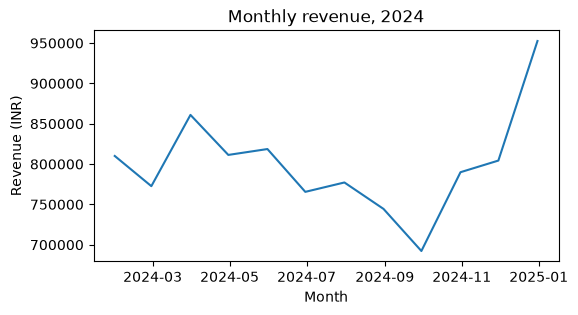

In [2]:
fig, ax = plt.subplots(figsize=(6, 3))     # width, height in inches
ax.plot(monthly.index, monthly.values)
ax.set_title("Monthly revenue, 2024")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (INR)")
plt.show()

Four lines of setup produce a complete, labelled chart. `plt.show()` displays the figure; in a notebook it also stops Matplotlib from printing the return value of the last call.

You will also see a shorter "pyplot" style in tutorials: `plt.plot(...)`, `plt.title(...)`. It draws on whichever axes is "current", which gets confusing as soon as there is more than one plot. The object-oriented style says exactly which axes you mean.

In [3]:
print(type(fig).__name__, type(ax).__name__)
print("figure size in inches:", fig.get_size_inches())

Figure Axes
figure size in inches: [6. 3.]


## 10.2 Line and scatter plots

Use a **line plot** when the x-axis has a natural order, usually time, and you want to see the trend. Calling `ax.plot` several times on the same axes draws several lines; give each a `label=` and call `ax.legend()`.

In [4]:
stores = pd.read_csv("data/stores.csv")
orders = orders.merge(stores[["store_id", "city"]], on="store_id")
weekly_city = (orders.set_index("timestamp")
               .groupby("city")["revenue"].resample("W").sum()
               .unstack(level=0)
               .iloc[:-1])                     # drop the partial last week (see 9.5)
print(weekly_city.head(3))

city        Bengaluru  Mumbai   Pune
timestamp                           
2024-01-07      33590   71170  85810
2024-01-14      37470   61900  85840
2024-01-21      36440   62800  73060


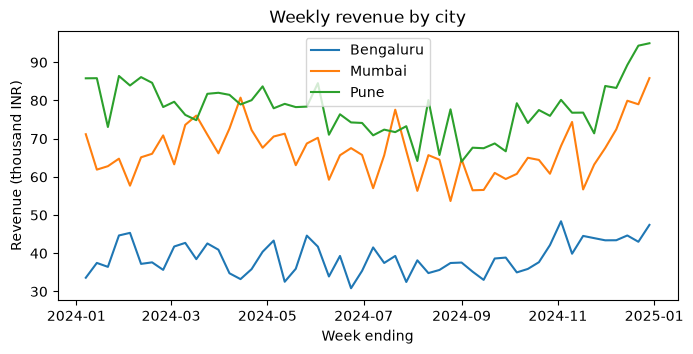

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for city in weekly_city.columns:
    ax.plot(weekly_city.index, weekly_city[city] / 1000, label=city)
ax.set_title("Weekly revenue by city")
ax.set_xlabel("Week ending")
ax.set_ylabel("Revenue (thousand INR)")
ax.legend()
plt.show()

Pune has two stores, so it earns the most; all three cities dip during the monsoon and rise in December.

Use a **scatter plot** to see whether two numbers move together. Each point is one observation. Here each point is one city on one day, with its temperature and revenue.

In [6]:
weather = pd.read_csv("data/weather.csv", parse_dates=["date"])
orders["date"] = orders["timestamp"].dt.normalize()
city_day = orders.groupby(["date", "city"], as_index=False)["revenue"].sum()
city_day = city_day.merge(weather, on=["date", "city"])
print(city_day.head(3))

        date       city  revenue  temp_c  rain_mm
0 2024-01-01  Bengaluru     4170    20.8      0.0
1 2024-01-01     Mumbai    10980    24.0      2.6
2 2024-01-01       Pune    12120    23.4      0.0


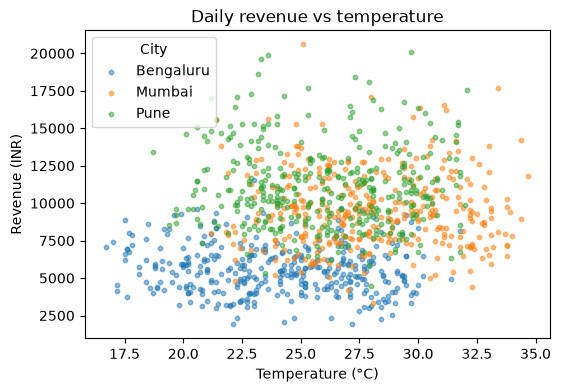

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
for city in ["Bengaluru", "Mumbai", "Pune"]:
    part = city_day[city_day["city"] == city]
    ax.scatter(part["temp_c"], part["revenue"], s=10, alpha=0.5, label=city)
ax.set_title("Daily revenue vs temperature")
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Revenue (INR)")
ax.legend(title="City")
plt.show()

`s=` sets the marker size and `alpha=` makes points see-through so overlapping clouds stay readable. Bengaluru (one small store) sits lowest and Pune (two stores) highest, but the clouds overlap a lot. Within each city the cloud is wide and nearly flat, so temperature on its own says little about total revenue.

## 10.3 Bar charts and histograms

A **bar chart** compares a number across categories. `ax.bar` draws vertical bars and `ax.barh` horizontal ones. Horizontal bars are easier to read when the labels are long or there are many categories. Sort the values first so the reader can rank them at a glance.

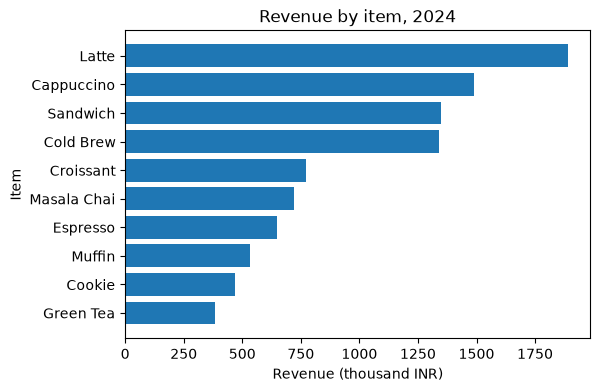

In [8]:
item_rev = orders.groupby("item")["revenue"].sum().sort_values()

fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(item_rev.index, item_rev.values / 1000)
ax.set_title("Revenue by item, 2024")
ax.set_xlabel("Revenue (thousand INR)")
ax.set_ylabel("Item")
plt.show()

The longest bar is at the top because `barh` draws the first category at the bottom, and we sorted from smallest to largest.

A **histogram** shows how a single number is distributed: it cuts the range into `bins` and draws a bar for how many values fall into each bin. Here is the distribution of daily revenue for the whole chain.

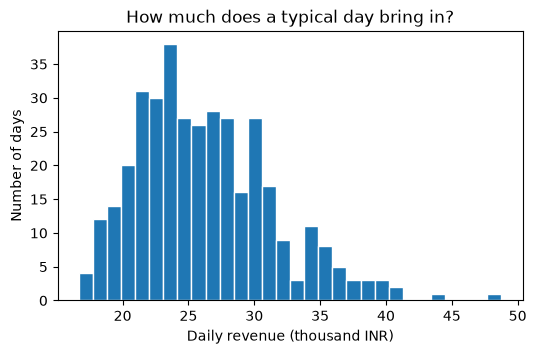

In [9]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(daily.values / 1000, bins=30, edgecolor="white")
ax.set_title("How much does a typical day bring in?")
ax.set_xlabel("Daily revenue (thousand INR)")
ax.set_ylabel("Number of days")
plt.show()

Most days earn between about 20 and 34 thousand rupees, with a tail of very busy days to the right. Try changing `bins`: too few hide the shape, too many make it look spiky.

## 10.4 Labels, ticks, legends and annotations

A chart is only useful if the reader knows what they are looking at. Always set a title and both axis labels, and include units. Beyond that, three tools tidy up a chart:

- **Tick formatters** change how tick labels look, for example `25,000` instead of `25000`, or month names on a date axis.
- **Legend options** such as `loc=` and `title=` place and name the legend.
- **Annotations** (`ax.annotate`) point an arrow at something and explain it.

In [10]:
best_day = daily.idxmax()
print("busiest day:", best_day.date(), best_day.day_name(), daily.max())

busiest day: 2024-12-28 Saturday 48770


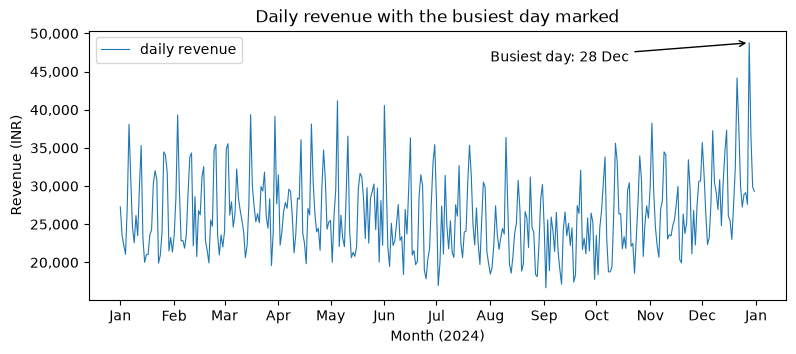

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(daily.index, daily.values, linewidth=0.8, label="daily revenue")
ax.annotate(f"Busiest day: {best_day:%d %b}",
            xy=(best_day, daily.max()),                         # the point
            xytext=(pd.Timestamp("2024-08-01"), daily.max() * 0.95),  # the text
            arrowprops={"arrowstyle": "->"})
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_title("Daily revenue with the busiest day marked")
ax.set_xlabel("Month (2024)")
ax.set_ylabel("Revenue (INR)")
ax.legend(loc="upper left")
plt.show()

The y-axis now has thousands separators, the x-axis shows one tick per month, and the arrow tells the reader what to look at. `xy` is the point being labelled and `xytext` is where the text sits, both in data coordinates.

For plain category labels you can set the ticks directly with `set_xticks` and `set_xticklabels`, and rotate long labels so they do not overlap:

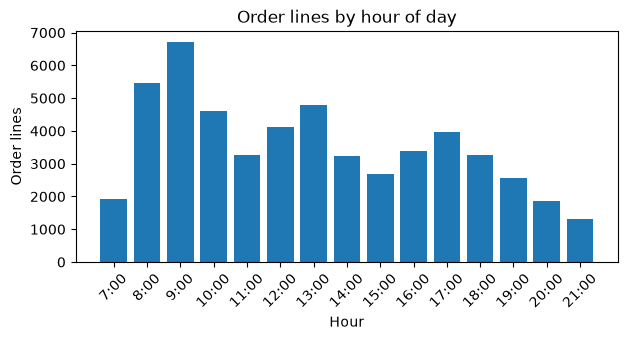

In [12]:
hours = orders["timestamp"].dt.hour.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(hours.index, hours.values)
ax.set_xticks(hours.index)
ax.set_xticklabels([f"{h}:00" for h in hours.index], rotation=45)
ax.set_title("Order lines by hour of day")
ax.set_xlabel("Hour")
ax.set_ylabel("Order lines")
plt.show()

## 10.5 Colours and styles

Every drawing method accepts style arguments. The ones you will use most:

| Argument | Example values |
|---|---|
| `color=` | `"tab:orange"`, `"#1f77b4"`, `"gray"` |
| `linestyle=` | `"-"`, `"--"`, `":"`, `"-."` |
| `linewidth=` | `0.5`, `2` |
| `marker=` | `"o"`, `"s"`, `"^"`, `"x"` |
| `alpha=` | `0` (invisible) to `1` (solid) |

The `"tab:..."` colours (`tab:blue`, `tab:orange`, `tab:green` and so on) are Matplotlib's default cycle; they are distinct and fairly colour-blind friendly. Use colour to carry meaning: highlight one thing and grey out the rest.

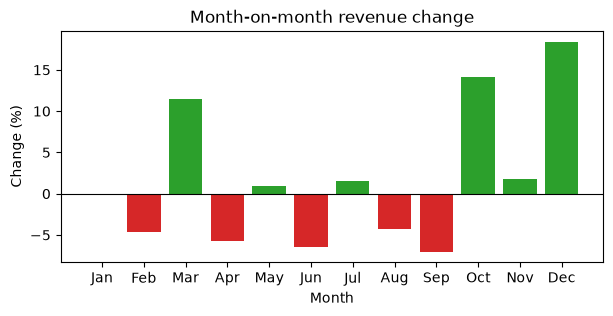

In [13]:
pct = monthly.pct_change() * 100
colors = ["tab:green" if v > 0 else "tab:red" for v in pct.fillna(0)]

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(monthly.index.strftime("%b"), pct.fillna(0), color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Month-on-month revenue change")
ax.set_xlabel("Month")
ax.set_ylabel("Change (%)")
plt.show()

Green bars are growth and red bars are decline; the thin black line at zero (`axhline`) gives the eye a baseline. January has no previous month, so it shows as 0.

**Style sheets** change the look of everything at once. `plt.style.available` lists them; `plt.style.context(...)` applies one only inside a `with` block, so the rest of the notebook keeps the default look.

['Solarize_Light2', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight']


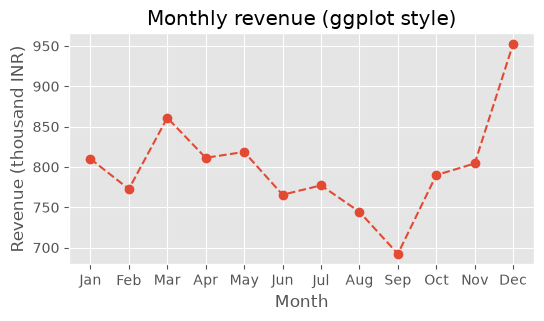

In [14]:
print(plt.style.available[:6])

with plt.style.context("ggplot"):
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.plot(monthly.index.strftime("%b"), monthly / 1000, marker="o", linestyle="--")
    ax.set_title("Monthly revenue (ggplot style)")
    ax.set_xlabel("Month")
    ax.set_ylabel("Revenue (thousand INR)")
    plt.show()

## 10.6 Grids of subplots

To compare several related charts, put them side by side in one figure. `plt.subplots(nrows, ncols)` returns a figure and an **array** of axes (a NumPy array, see Chapter 1), which you index like any 2-D array. `sharex=True` and `sharey=True` make the panels use the same scale, so you compare like with like.

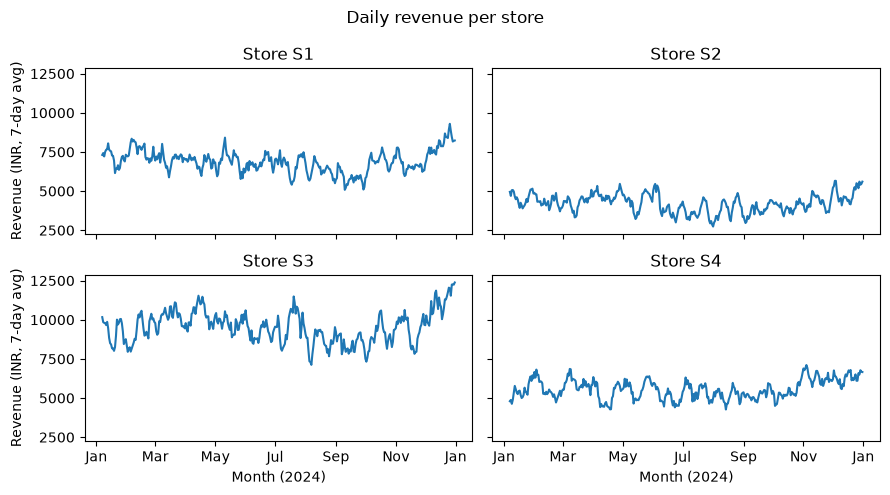

In [15]:
store_daily = (orders.set_index("timestamp")
               .groupby("store_id")["revenue"].resample("D").sum()
               .unstack(level=0))

fig, axes = plt.subplots(2, 2, figsize=(9, 5), sharex=True, sharey=True)
for ax, store in zip(axes.ravel(), store_daily.columns):
    ax.plot(store_daily.index, store_daily[store].rolling(7).mean())
    ax.set_title(f"Store {store}")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
for ax in axes[1, :]:
    ax.set_xlabel("Month (2024)")
for ax in axes[:, 0]:
    ax.set_ylabel("Revenue (INR, 7-day avg)")
fig.suptitle("Daily revenue per store")
fig.tight_layout()
plt.show()

`axes.ravel()` flattens the 2x2 grid so one loop can visit every panel. Because the y-axis is shared, you can see straight away that S3 (Mumbai) is the biggest store and S2 the smallest. `fig.suptitle` titles the whole figure, and `fig.tight_layout()` nudges panels apart so labels do not collide.

## 10.7 Twin axes: two units on one chart

Sometimes you want two series with different units on one time axis, for example revenue in rupees and temperature in degrees. `ax.twinx()` creates a second axes that shares the x-axis but has its own y-axis on the right.

In [16]:
pune = city_day[city_day["city"] == "Pune"].set_index("date")
pune_month = pune.resample("ME").agg({"revenue": "sum", "temp_c": "mean", "rain_mm": "sum"})
print(pune_month.round(1).head(3))

            revenue  temp_c  rain_mm
date                                
2024-01-31   359460    23.2      5.0
2024-02-29   342120    24.5     19.2
2024-03-31   357040    26.9     13.8


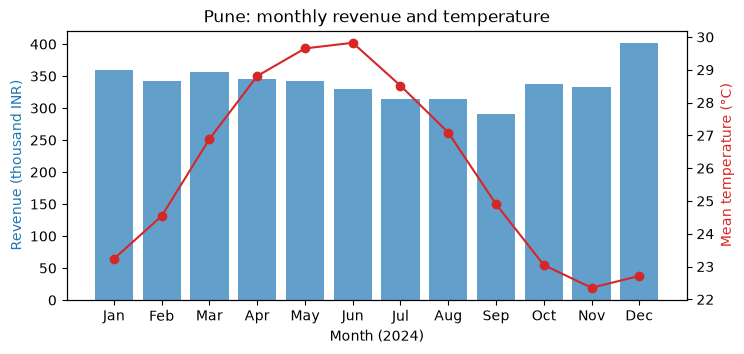

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.5))
months = pune_month.index.strftime("%b")
ax.bar(months, pune_month["revenue"] / 1000, color="tab:blue", alpha=0.7)
ax.set_xlabel("Month (2024)")
ax.set_ylabel("Revenue (thousand INR)", color="tab:blue")

ax2 = ax.twinx()
ax2.plot(months, pune_month["temp_c"], color="tab:red", marker="o")
ax2.set_ylabel("Mean temperature (°C)", color="tab:red")
ax.set_title("Pune: monthly revenue and temperature")
plt.show()

Colouring each axis label to match its series tells the reader which scale belongs to which data. Use twin axes sparingly: two scales on one chart can suggest a relationship that is just a coincidence of where the axes start. Here temperature peaks in May and June, while revenue is lowest from June to September. Those are the monsoon months, so the rain (see 9.8), not the heat, is the more likely cause of the dip.

## 10.8 The pandas shortcut, and saving figures

pandas Series and DataFrames have a `.plot()` method that calls Matplotlib for you. It uses the index as the x-axis and draws one line (or bar) per column, with a legend. It returns the Axes, so you can still label it the usual way.

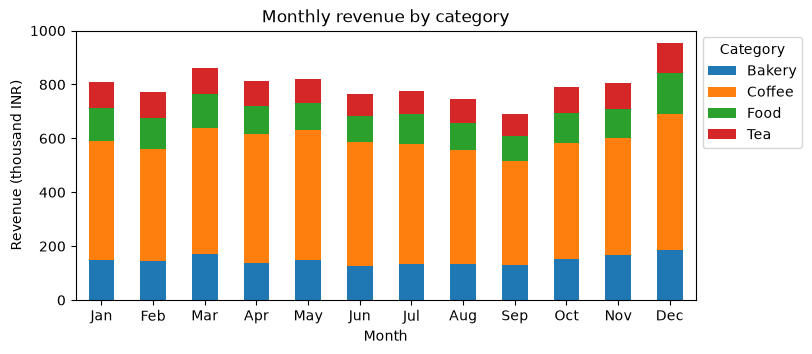

In [18]:
cat_month = (orders.set_index("timestamp")
             .groupby("category")["revenue"].resample("ME").sum()
             .unstack(level=0))
cat_month.index = cat_month.index.strftime("%b")

ax = (cat_month / 1000).plot(kind="bar", stacked=True, rot=0, figsize=(8, 3.5))
ax.set_title("Monthly revenue by category")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (thousand INR)")
ax.legend(title="Category", loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

One call gave a stacked bar chart with a legend; `rot=0` keeps the month labels horizontal. Coffee is by far the biggest slice every month. `kind=` can be `"line"`, `"bar"`, `"barh"`, `"hist"`, `"scatter"` and more. The shortcut is great for quick looks; switch to `fig, ax = plt.subplots()` when you need full control.

To keep a chart, call `fig.savefig`. The file type comes from the extension: `.png` for images, `.svg` or `.pdf` for sharp vector graphics. `dpi=` controls resolution and `bbox_inches="tight"` trims empty margins. We save into a temporary folder so nothing is left behind.

In [19]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(monthly.index.strftime("%b"), monthly / 1000, marker="o")
ax.set_title("Monthly revenue")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (thousand INR)")

with tempfile.TemporaryDirectory() as tmp:
    path = os.path.join(tmp, "monthly_revenue.png")
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print("saved", os.path.basename(path), os.path.getsize(path) > 0)
plt.close(fig)   # we only wanted the file, so do not display it

saved monthly_revenue.png True


Call `savefig` **before** `plt.show()`: in scripts, `show` can leave you with an empty figure afterwards.

## 10.9 Common mistakes

| Mistake | What happens | Fix |
|---|---|---|
| Mixing `plt.title(...)` and `ax.` calls with several plots | Labels land on the wrong panel | Use the `fig, ax = plt.subplots()` style and call methods on `ax` |
| No title, axis labels or units | Readers cannot tell what the chart shows | Always `set_title`, `set_xlabel`, `set_ylabel` with units |
| Calling `ax.legend()` without `label=` | Warning and an empty legend | Pass `label=` to each plot call |
| Overlapping labels in a grid | Titles and tick labels collide | `fig.tight_layout()` |
| Comparing panels with different y-scales | Small stores look as big as large ones | `sharey=True` |
| `savefig` after `plt.show()` | An empty image file in scripts | Save first, then show |

## 10.10 Cheat sheet

| Task | Code |
|---|---|
| New figure and axes | `fig, ax = plt.subplots(figsize=(6, 3))` |
| Line / scatter | `ax.plot(x, y)`, `ax.scatter(x, y, s=10, alpha=0.5)` |
| Bars | `ax.bar(labels, values)`, `ax.barh(labels, values)` |
| Histogram | `ax.hist(values, bins=30)` |
| Title and labels | `ax.set_title(...)`, `ax.set_xlabel(...)`, `ax.set_ylabel(...)` |
| Legend | `ax.plot(..., label="x")`, then `ax.legend()` |
| Thousands separator | `ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))` |
| Month names on a date axis | `ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))` |
| Rotate tick labels | `ax.tick_params(axis="x", rotation=45)` |
| Arrow with text | `ax.annotate("text", xy=(x, y), xytext=(x2, y2), arrowprops={"arrowstyle": "->"})` |
| Reference line | `ax.axhline(0)`, `ax.axvline(x)` |
| Grid of plots | `fig, axes = plt.subplots(2, 2, sharex=True, sharey=True)` |
| Second y-axis | `ax2 = ax.twinx()` |
| pandas shortcut | `df.plot(kind="bar", ax=ax)` |
| Save | `fig.savefig("chart.png", dpi=150, bbox_inches="tight")` |

## 10.11 Exercises

**1.** Draw a bar chart of total revenue by **payment method** (UPI, Card, Cash), sorted from largest to smallest, with a title and axis labels.

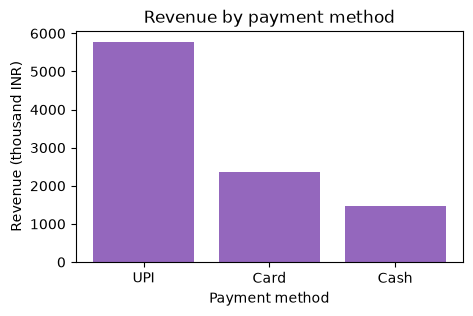

In [20]:
# Solution
pay = orders.groupby("payment")["revenue"].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(pay.index, pay.values / 1000, color="tab:purple")
ax.set_title("Revenue by payment method")
ax.set_xlabel("Payment method")
ax.set_ylabel("Revenue (thousand INR)")
plt.show()

**2.** Plot a histogram of the `temp_c` column of `weather`, one colour per city, on the same axes. Use `alpha=0.5` and a legend so the overlapping parts stay visible.

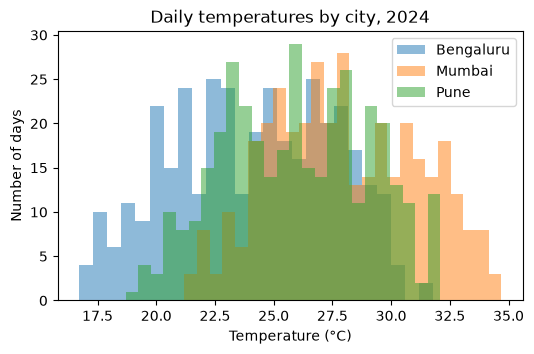

In [21]:
# Solution
fig, ax = plt.subplots(figsize=(6, 3.5))
for city, part in weather.groupby("city"):
    ax.hist(part["temp_c"], bins=25, alpha=0.5, label=city)
ax.set_title("Daily temperatures by city, 2024")
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Number of days")
ax.legend()
plt.show()

**3.** Make a 1x2 figure. On the left, plot the number of order lines per hour of day. On the right, plot the number of order lines per day of the week (Monday first). Give each panel its own title and labels, and the whole figure a `suptitle`.

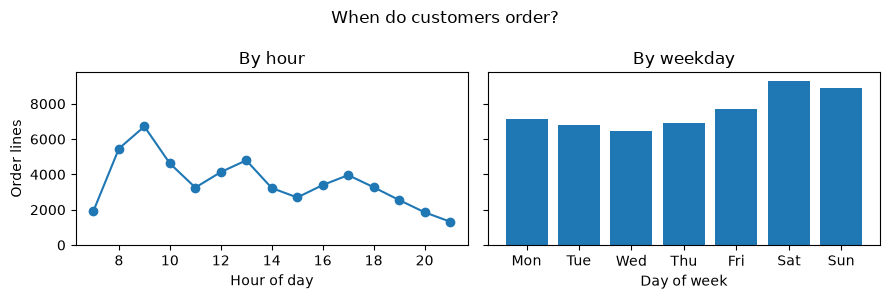

In [22]:
# Solution
by_dow = orders["timestamp"].dt.day_of_week.value_counts().sort_index()
fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
left.plot(hours.index, hours.values, marker="o")
left.set_title("By hour")
left.set_xlabel("Hour of day")
left.set_ylabel("Order lines")
right.bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], by_dow.values)
right.set_title("By weekday")
right.set_xlabel("Day of week")
fig.suptitle("When do customers order?")
fig.tight_layout()
plt.show()

**4.** Save the chart from exercise 1 as an SVG file in a temporary folder and print the file size in kilobytes.

In [23]:
# Solution
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(pay.index, pay.values / 1000)
ax.set_title("Revenue by payment method")
ax.set_xlabel("Payment method")
ax.set_ylabel("Revenue (thousand INR)")
with tempfile.TemporaryDirectory() as tmp:
    path = os.path.join(tmp, "payments.svg")
    fig.savefig(path)
    print(f"{os.path.getsize(path) / 1024:.1f} KB")
plt.close(fig)

26.5 KB
